In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import hvplot.xarray
# from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm
from scipy.optimize import curve_fit

### Checking Old Calibration

In [4]:
calib_dir = 'C:/Users/RalphGroup/Documents/group_code/daedalus_control/calibrations/'
base_volt_coeff= np.loadtxt(calib_dir + 'daedalus_volt_center_calib.csv', delimiter=',')
base_volt_calib = np.poly1d(base_volt_coeff)

In [12]:
base_volt_coeff

array([ 5.07090790e+05,  9.90911947e+03, -1.23877768e+05, -1.87082708e+03,
        1.10891163e+04,  1.18277155e+02, -1.75379828e+02, -1.14702258e+00,
        2.30928445e+01,  4.99274863e-02])

In [8]:
measured = pd.read_csv('./2024-07-17/test_daedalus_voltCenter_calib_2024-07-17_1.csv', comment = '#')

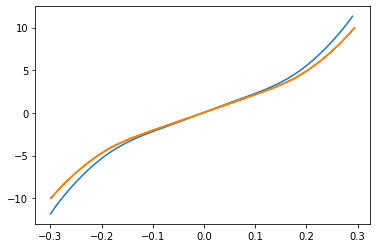

In [10]:
fields = np.arange(-0.3, 0.3, 0.01)
plt.plot(fields, base_volt_calib(fields))
plt.plot(measured['Xfield'], measured['V'])

### Fit new Calibration

[ 2.75881895e+05  6.43121285e+03 -7.65105559e+04 -1.35929819e+03
  7.82508256e+03  9.70344664e+01 -1.45462329e+02 -1.10471669e+00
  2.14692538e+01  5.15295145e-02]


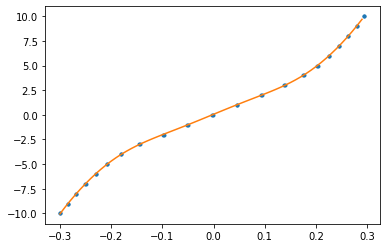

In [21]:
base_volt_coeff_new = np.polyfit(measured['Xfield'], measured['V'], 9)
base_volt_calib_new = np.poly1d(base_volt_coeff_new)
print(base_volt_coeff_new)
plt.plot(measured['Xfield'], measured['V'], '.')
fields = np.arange(-0.3, 0.3, 0.01)
plt.plot(fields, base_volt_calib_new(fields))

### Compare with old calibration

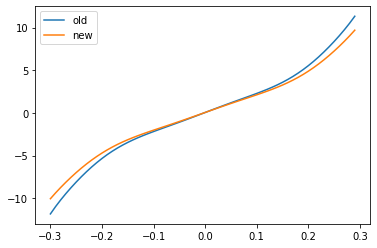

In [22]:
plt.plot(fields, base_volt_calib(fields), label = 'old')
plt.plot(fields, base_volt_calib_new(fields), label = 'new')
plt.legend()

### Fine steps

[ 2.67998879e+05  5.76602968e+03 -7.54013318e+04 -1.23571710e+03
  7.78007285e+03  8.86964487e+01 -1.45283681e+02 -9.10596441e-01
  2.14689995e+01  5.12205619e-02]


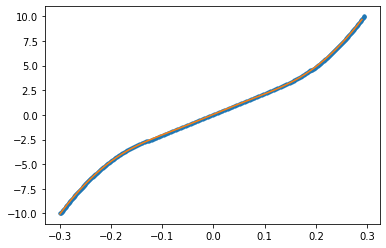

In [23]:
fine0deg = pd.read_csv('./2024-07-17/phi0_daedalus_voltCenter_calib_2024-07-17_1.csv', comment = '#')
base_volt_coeff_new = np.polyfit(fine0deg['Xfield'], fine0deg['V'], 9)
base_volt_calib_new = np.poly1d(base_volt_coeff_new)
print(base_volt_coeff_new)
plt.plot(fine0deg['Xfield'], fine0deg['V'], '.')
fields = np.arange(-0.3, 0.3, 0.01)
plt.plot(fields, base_volt_calib_new(fields))

### Check with 90deg

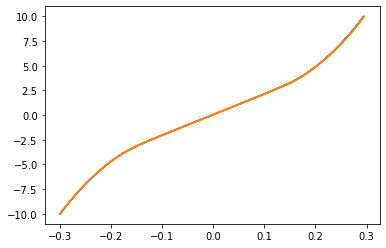

In [25]:
fine0deg = pd.read_csv('./2024-07-17/phi0_daedalus_voltCenter_calib_2024-07-17_1.csv', comment = '#')
fine90deg = pd.read_csv('./2024-07-17/phi90_daedalus_voltCenter_calib_2024-07-17_1.csv', comment = '#')
plt.plot(fine0deg['Xfield'], fine0deg['V'])
plt.plot(fine90deg['Yfield'], fine90deg['V'])